In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
# fix state
rng = np.random.default_rng(42)

In [77]:
# создаем станции в соте
def create_stations(num_cells=3, area_size=1000.0):
    cells = rng.random((num_cells, 2)) * area_size    
    return cells

### Расчет затухания (Path Loss)
Логарифмическая модель затухания, дБ

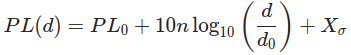

Затухание на опорном расстоянии (1 м)

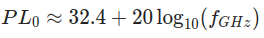


In [78]:
# расчет затухания на расстоянии
def pathloss_db(distance_m, frequency_ghz=1.8, n=3.0, sigma_db=4.0):
    # минимальное расстояние больше 1 м
    d = np.maximum(distance_m, 1.0)

    # приблизительное затухание на 1 метре (опорное расстояние)
    pl0 = 32.4 + 20 * np.log10(frequency_ghz)

    # случайное затухание из-за препятствий
    shadow = rng.normal(0.0, sigma_db, size=d.shape)

    pl = pl0 + 10 * n * np.log10(d) + shadow

    return pl

In [79]:
cells = create_stations()

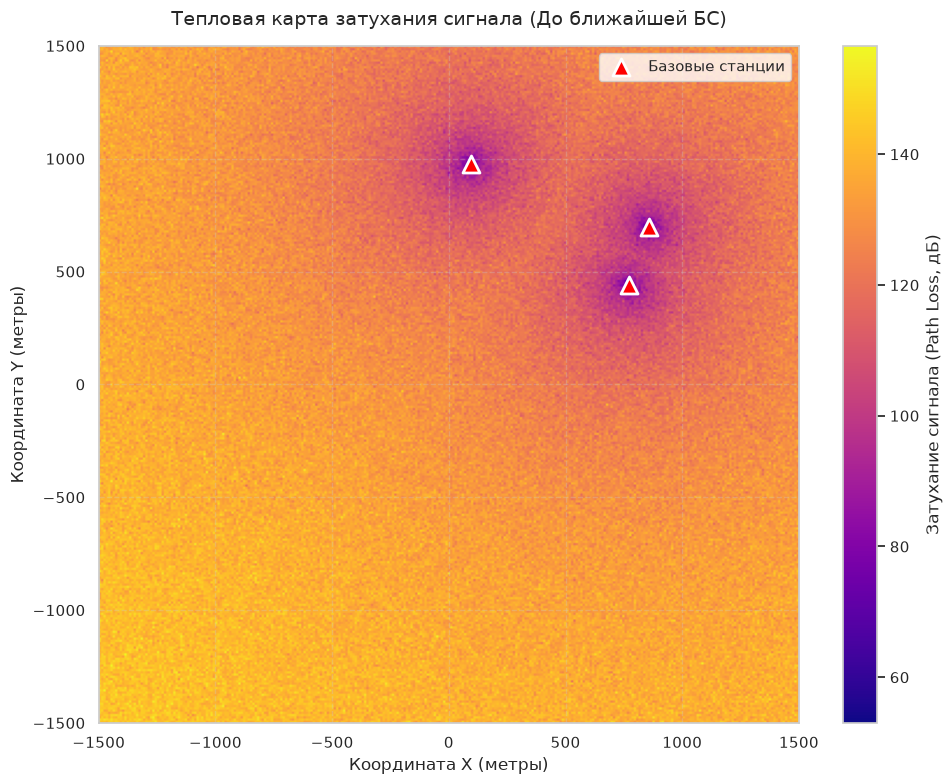

In [80]:

# Настройки области и генератора
MIN_COORD = -1500.0
MAX_COORD = 1500.0
RESOLUTION = 10.0   # Шаг сетки в метрах

# Создаем двумерную сетку точек (X, Y) для карты
x_coords = np.arange(MIN_COORD, MAX_COORD + RESOLUTION, RESOLUTION)
y_coords = np.arange(MIN_COORD, MAX_COORD + RESOLUTION, RESOLUTION)
X, Y = np.meshgrid(x_coords, y_coords)

# Превращаем сетку в плоский список точек для векторных расчетов (N_points, 2)
grid_points = np.vstack([X.ravel(), Y.ravel()]).T

# Считаем расстояния от каждой точки сетки до каждой БС
distances_to_all_cells = np.linalg.norm(cells[:, np.newaxis, :] - grid_points[np.newaxis, :, :], axis=2)

# Находим минимальное расстояние до ближайшей БС для каждой точки
min_distances = np.min(distances_to_all_cells, axis=0)

# Считаем затухание для этих кратчайших расстояний
pl_flat = pathloss_db(min_distances, frequency_ghz=2.4, n=3.0, sigma_db=4.0)

# Возвращаем матрице затуханий форму исходной сетки (для отрисовки)
PL_grid = pl_flat.reshape(X.shape)

plt.figure(figsize=(10, 8), dpi=100)
extent = [MIN_COORD, MAX_COORD, MIN_COORD, MAX_COORD]
im = plt.imshow(PL_grid, extent=extent, origin='lower', cmap='plasma', aspect='auto')

cbar = plt.colorbar(im)
cbar.set_label('Затухание сигнала (Path Loss, дБ)', fontsize=12)

# Наносим базовые станции поверх карты
plt.scatter(cells[:, 0], cells[:, 1], color='red', marker='^', s=150, edgecolor='white', linewidth=2, label='Базовые станции')

# Оформление осей
plt.title('Тепловая карта затухания сигнала (До ближайшей БС)', fontsize=14, pad=15)
plt.xlabel('Координата X (метры)', fontsize=12)
plt.ylabel('Координата Y (метры)', fontsize=12)
plt.xlim(MIN_COORD, MAX_COORD)
plt.ylim(MIN_COORD, MAX_COORD)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


### RSRP (Reference Signal Received Power) - уровень полезного сигнала от соты, который видит пользователь.



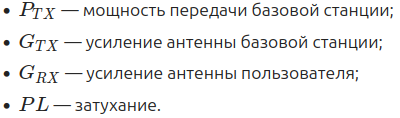

In [81]:
# Исходные данные
tx_power_dbm = 43.0 # 20 Вт
antenna_gain_db = 0.0
user_gain_db = 0.0

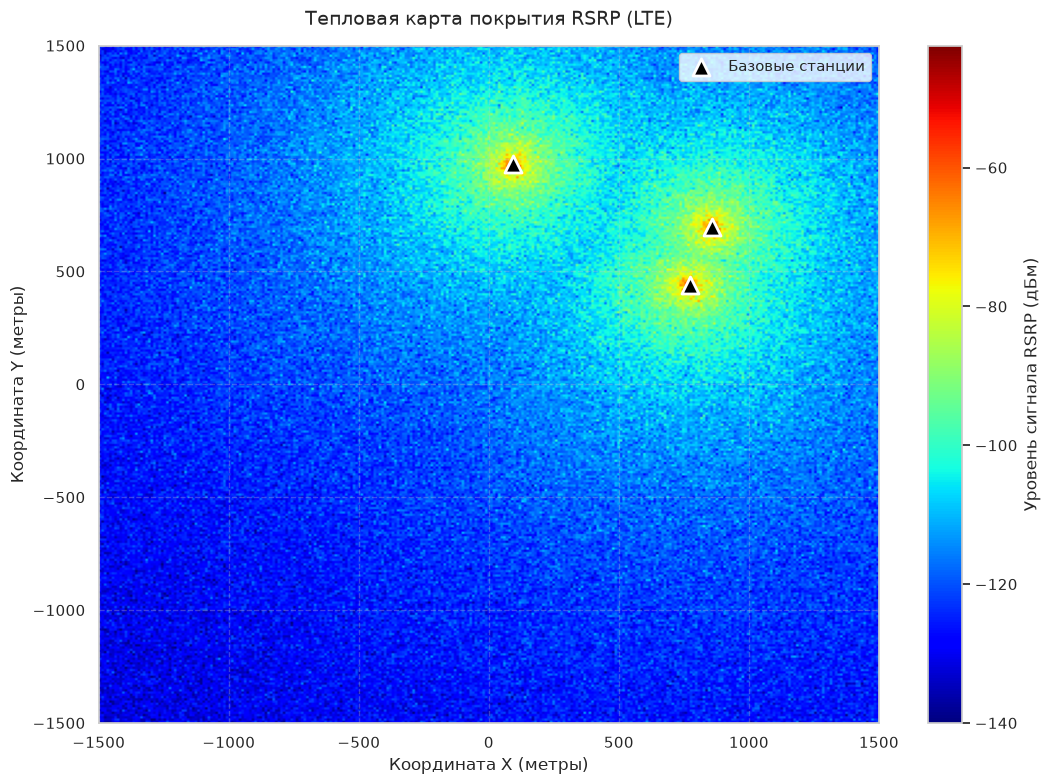

In [82]:
# Пересчет полной мощности БС в мощность на одну поднесущую (для полосы 20 МГц = 1200 поднесущих)
# Мощность уменьшается на 10 * log10(1200) ≈ 30.8 дБ
num_subcarriers = 1200 
tx_power_per_re_dbm = tx_power_dbm - 10 * np.log10(num_subcarriers)

# Границы карты
MIN_COORD = -1500.0
MAX_COORD = 1500.0
RESOLUTION = 10.0 

x_coords = np.arange(MIN_COORD, MAX_COORD + RESOLUTION, RESOLUTION)
y_coords = np.arange(MIN_COORD, MAX_COORD + RESOLUTION, RESOLUTION)
X, Y = np.meshgrid(x_coords, y_coords)
grid_points = np.vstack([X.ravel(), Y.ravel()]).T

# Расчет расстояний и Path Loss
distances_to_all_cells = np.linalg.norm(cells[:, np.newaxis, :] - grid_points[np.newaxis, :, :], axis=2)
min_distances = np.min(distances_to_all_cells, axis=0)
pl_flat = pathloss_db(min_distances, frequency_ghz=2.4, n=3.0, sigma_db=4.0)

# Применяем формулу баланса мощностей
rsrp_flat = tx_power_per_re_dbm - pl_flat + antenna_gain_db + user_gain_db
RSRP_grid = rsrp_flat.reshape(X.shape)

plt.figure(figsize=(11, 8), dpi=100)

extent = [MIN_COORD, MAX_COORD, MIN_COORD, MAX_COORD]

# Ограничим отображение снизу на уровне -140 дБм (предел чувствительности LTE приемников)
RSRP_grid_clipped = np.clip(RSRP_grid, -140, None)
im = plt.imshow(RSRP_grid_clipped, extent=extent, origin='lower', cmap='jet', aspect='auto')

# Настройка шкалы уровней (Colorbar)
cbar = plt.colorbar(im)
cbar.set_label('Уровень сигнала RSRP (дБм)', fontsize=12)

# Наносим базовые станции
plt.scatter(cells[:, 0], cells[:, 1], color='black', marker='^', s=150, edgecolor='white', linewidth=2, label='Базовые станции')

# Оформление
plt.title('Тепловая карта покрытия RSRP (LTE)', fontsize=14, pad=15)
plt.xlabel('Координата X (метры)', fontsize=12)
plt.ylabel('Координата Y (метры)', fontsize=12)
plt.xlim(MIN_COORD, MAX_COORD)
plt.ylim(MIN_COORD, MAX_COORD)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


## Signal-to-Interference-plus-Noise Ratio (Отношение сигнала к сумме интерференции и шума).

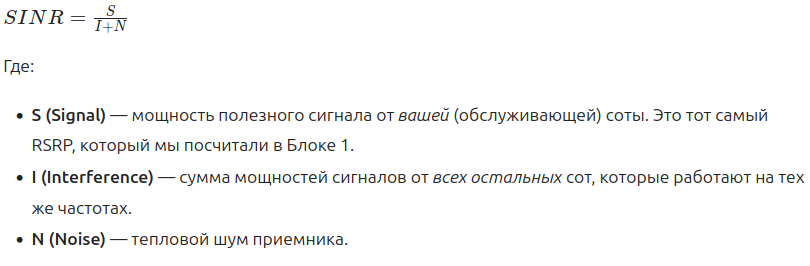

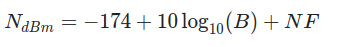

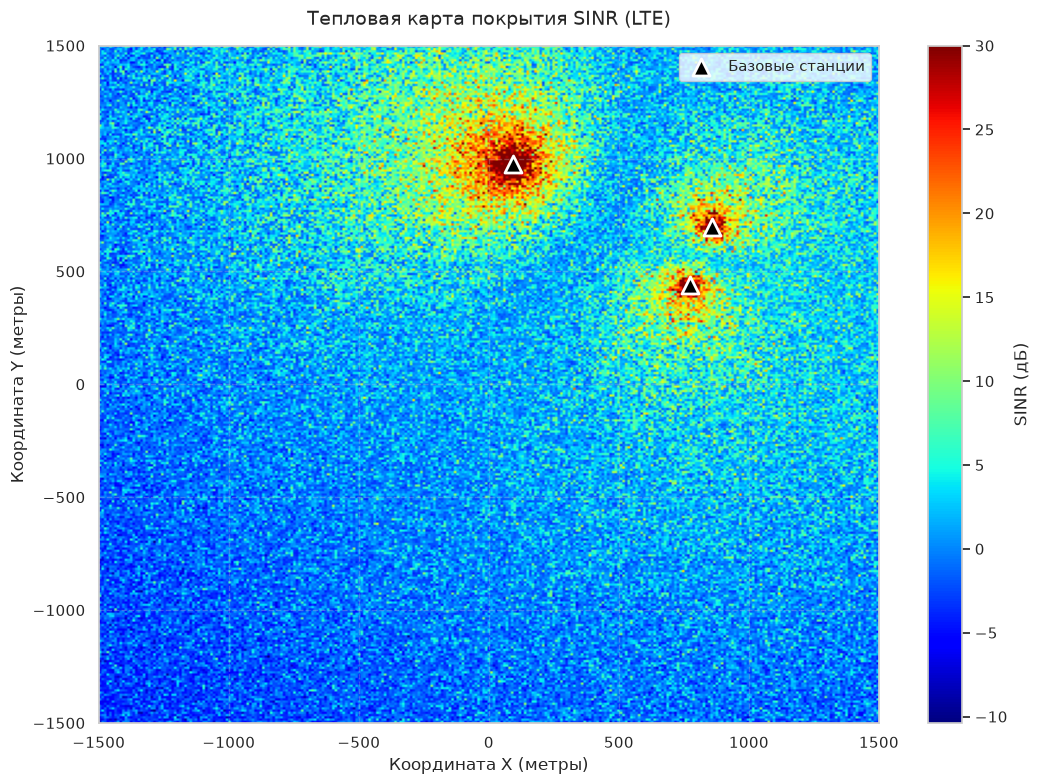

In [83]:
# Параметры шума для одной поднесущей.
# Для LTE поднесущая обычно 15 кГц.
subcarrier_bandwidth_hz = 15e3

# Тепловой шум: -174 дБм/Гц + 10*log10(полоса) + шумовая фигура приемника
noise_figure_db = 5.0
noise_dbm_per_sc = -174.0 + 10 * np.log10(subcarrier_bandwidth_hz) + noise_figure_db

# Перевод шума в мВт
noise_mw_per_sc = 10 ** (noise_dbm_per_sc / 10.0)

# Если distances_to_all_cells уже рассчитаны ранее, можно их использовать.
# Здесь на всякий случай пересчитаем расстояния до всех БС.
distances_to_all_cells = np.linalg.norm(
    cells[:, np.newaxis, :] - grid_points[np.newaxis, :, :],
    axis=2
)

# Защита от нулевой дистанции, если точка сетки совпала с координатами БС
distances_to_all_cells_safe = np.maximum(distances_to_all_cells, 1.0)

# Path Loss до каждой БС для каждой точки сетки
# Ожидается форма: [num_cells, num_grid_points]
pl_all = pathloss_db(
    distances_to_all_cells_safe,
    frequency_ghz=2.4,
    n=3.0,
    sigma_db=4.0
)

# Принятая мощность на поднесущей от каждой БС:
# [num_cells, num_grid_points]
rx_powers_all_dbm = (
    tx_power_per_re_dbm
    - pl_all
    + antenna_gain_db
    + user_gain_db
)

# Перевод мощностей в мВт
rx_powers_all_mw = 10 ** (rx_powers_all_dbm / 10.0)

# Определяем лучшую соту в каждой точке сетки.
# Лучшая сота - максимальный принятый уровень.
serving_cell_idx = np.argmax(rx_powers_all_dbm, axis=0)

# Индексы всех точек сетки
point_idx = np.arange(rx_powers_all_dbm.shape[1])

# Мощность полезного сигнала от лучшей соты
signal_dbm = rx_powers_all_dbm[serving_cell_idx, point_idx]
signal_mw = 10 ** (signal_dbm / 10.0)

# Суммарная принятая мощность от всех БС
total_rx_mw = np.sum(rx_powers_all_mw, axis=0)

# Межсотевая помеха: все БС, кроме лучшей в данной точке
interference_mw = np.maximum(total_rx_mw - signal_mw, 0.0)

# SINR в линейном масштабе
# Добавляем защиту от деления на ноль
sinr_linear = signal_mw / np.maximum(interference_mw + noise_mw_per_sc, 1e-300)

# SINR в дБ
sinr_db = 10 * np.log10(np.maximum(sinr_linear, np.finfo(float).tiny))

# Преобразование в сетку для отображения
SINR_grid = sinr_db.reshape(X.shape)

plt.figure(figsize=(11, 8), dpi=100)

extent = [MIN_COORD, MAX_COORD, MIN_COORD, MAX_COORD]

# Ограничим отображение, например, диапазоном от -20 до +30 дБ.
# Этот диапазон можно изменить по вашему усмотрению.
SINR_grid_clipped = np.clip(SINR_grid, -20, 30)

im = plt.imshow(
    SINR_grid_clipped,
    extent=extent,
    origin='lower',
    cmap='jet',
    aspect='auto'
)

# Цветовая шкала
cbar = plt.colorbar(im)
cbar.set_label('SINR (дБ)', fontsize=12)

# Наносим базовые станции
plt.scatter(
    cells[:, 0],
    cells[:, 1],
    color='black',
    marker='^',
    s=150,
    edgecolor='white',
    linewidth=2,
    label='Базовые станции'
)

# Оформление
plt.title('Тепловая карта покрытия SINR (LTE)', fontsize=14, pad=15)
plt.xlabel('Координата X (метры)', fontsize=12)
plt.ylabel('Координата Y (метры)', fontsize=12)
plt.xlim(MIN_COORD, MAX_COORD)
plt.ylim(MIN_COORD, MAX_COORD)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Добавляем пользователей (UE)

CDF (Cumulative Distribution Function)

CDF SINR - график, который показывает, какая доля пользователей имеет SINR ниже определенного значения.

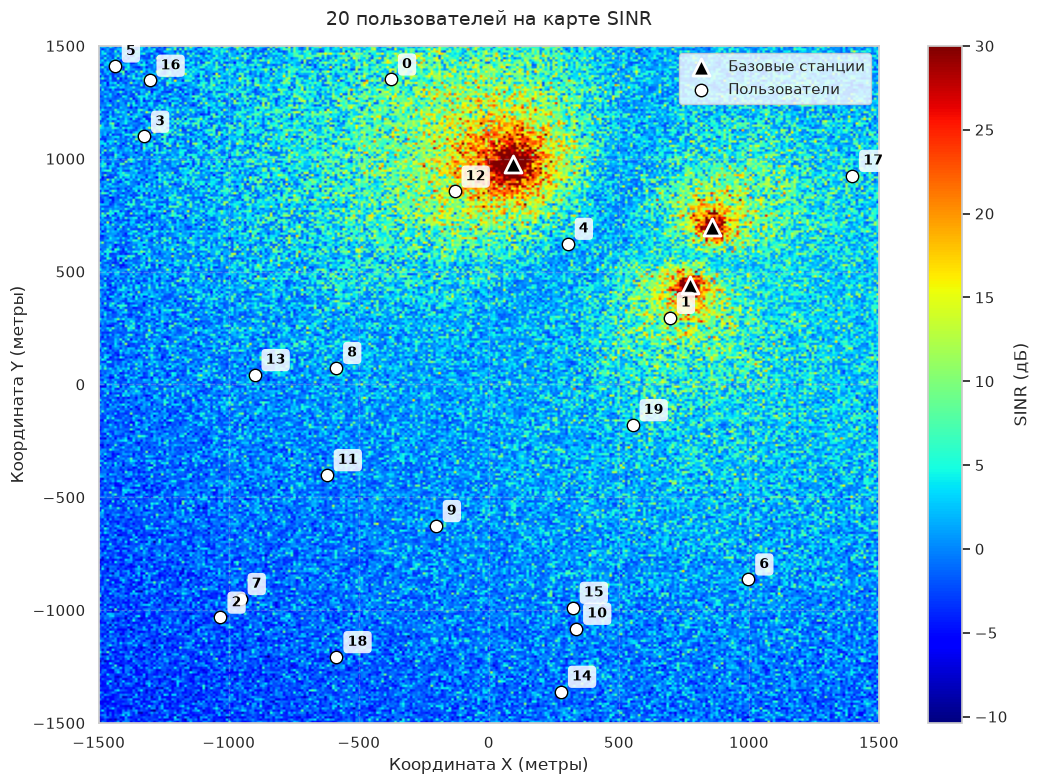

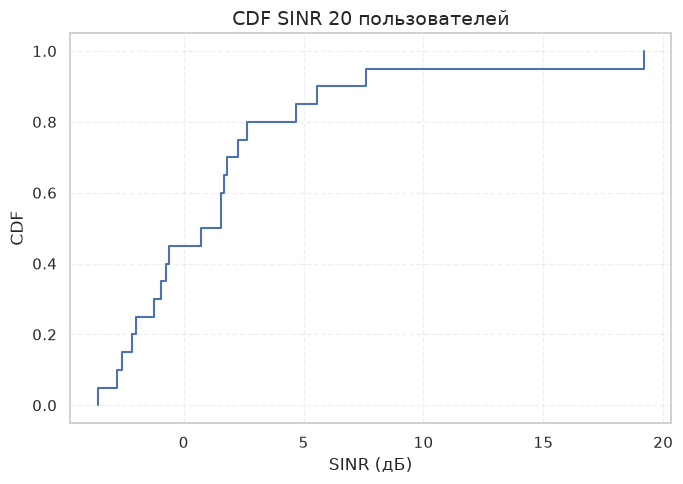

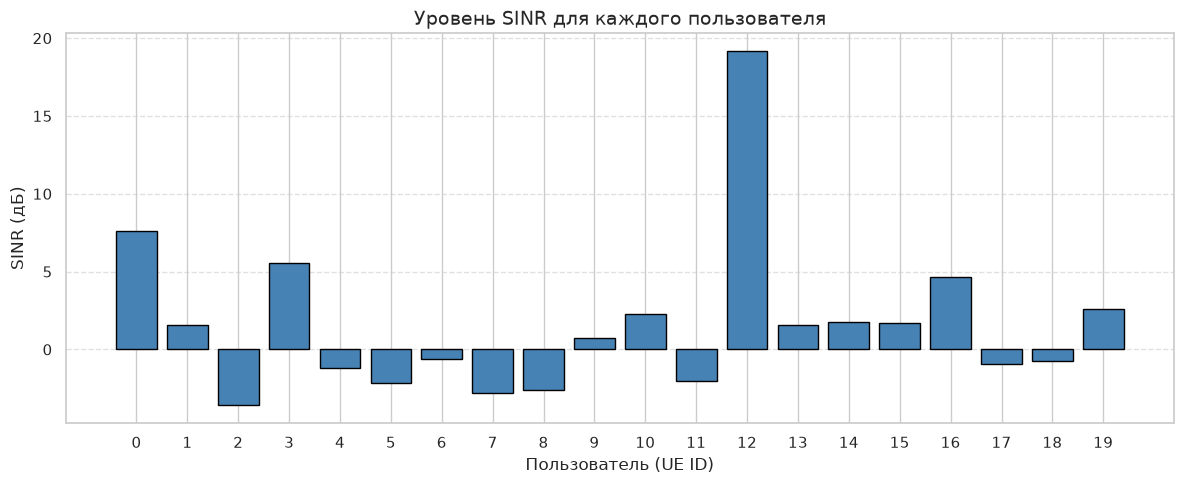

In [84]:
# Если шум еще не был рассчитан ранее
try:
    noise_mw_per_sc
except NameError:
    noise_mw_per_sc = 10 ** ((-174.0 + 10 * np.log10(15e3) + 5.0) / 10.0)

# 20 пользователей
n_users = 20
np.random.seed(42)
users = np.random.uniform(MIN_COORD, MAX_COORD, (n_users, 2))

# Расчет SINR пользователей через уже существующую pathloss_db
d = np.maximum(np.linalg.norm(cells[:, None, :] - users[None, :, :], axis=2), 1.0)
pl = pathloss_db(d.ravel(), frequency_ghz=2.4, n=3.0, sigma_db=4.0).reshape(d.shape)

rx_dbm = tx_power_per_re_dbm - pl + antenna_gain_db + user_gain_db
rx_mw = 10 ** (rx_dbm / 10.0)

serving_idx = np.argmax(rx_dbm, axis=0)
point_idx = np.arange(n_users)

signal_mw = rx_mw[serving_idx, point_idx]
interference_mw = np.maximum(rx_mw.sum(axis=0) - signal_mw, 0.0)

sinr_ue_db = 10 * np.log10(signal_mw / (interference_mw + noise_mw_per_sc))

# Отображение пользователей на карте SINR
plt.figure(figsize=(11, 8), dpi=100)

im = plt.imshow(
    np.clip(SINR_grid, -20, 30),
    extent=extent,
    origin='lower',
    cmap='jet',
    aspect='auto'
)

cbar = plt.colorbar(im)
cbar.set_label('SINR (дБ)', fontsize=12)

plt.scatter(
    cells[:, 0], cells[:, 1],
    color='black', marker='^', s=150,
    edgecolor='white', linewidth=2,
    label='Базовые станции'
)

plt.scatter(
    users[:, 0], users[:, 1],
    color='white', edgecolor='black',
    s=80, label='Пользователи'
)

for i in range(n_users):
    plt.annotate(
        str(i),                       # Текст (номер пользователя)
        (users[i, 0], users[i, 1]),   # Координаты точки
        fontsize=10,
        fontweight='bold',
        color='black',
        # Смещаем текст на 7 пикселей вправо и вверх, чтобы не закрывать маркер
        textcoords="offset points", 
        xytext=(8, 8),
        # Белая полупрозрачная подложка под текст для 100% читаемости
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='none')
    )

plt.title('20 пользователей на карте SINR', fontsize=14, pad=15)
plt.xlabel('Координата X (метры)', fontsize=12)
plt.ylabel('Координата Y (метры)', fontsize=12)
plt.xlim(MIN_COORD, MAX_COORD)
plt.ylim(MIN_COORD, MAX_COORD)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# CDF SINR пользователей
sinr_sorted = np.sort(sinr_ue_db)
cdf = np.arange(1, n_users + 1) / n_users

plt.figure(figsize=(7, 5))
plt.step(
    np.r_[sinr_sorted[0], sinr_sorted],
    np.r_[0, cdf],
    where='post'
)

plt.xlabel('SINR (дБ)', fontsize=12)
plt.ylabel('CDF', fontsize=12)
plt.title('CDF SINR 20 пользователей', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.bar(range(n_users), sinr_ue_db, color='steelblue', edgecolor='black')

plt.xlabel('Пользователь (UE ID)', fontsize=12)
plt.ylabel('SINR (дБ)', fontsize=12)
plt.title('Уровень SINR для каждого пользователя', fontsize=14)
plt.xticks(range(n_users))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Формула Шеннона

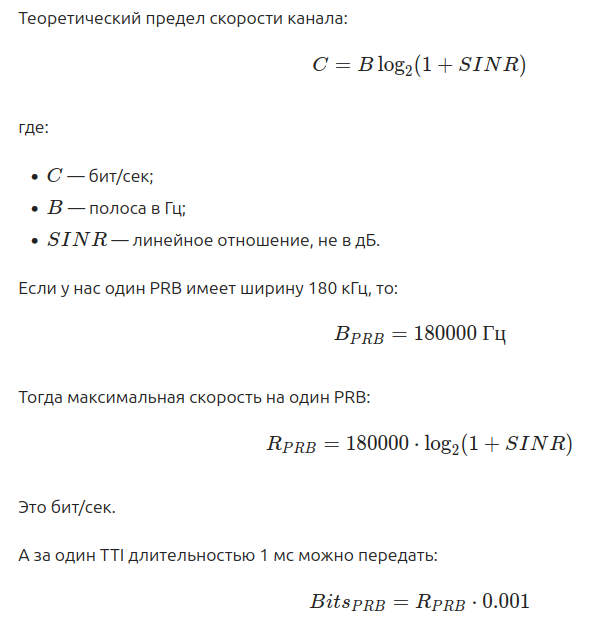

## Планирование ресурса (PRB)

In [85]:
# параметры MAC уровня
n_prb = 50
tti_duration_ms = 1.0
tti_duration_s = tti_duration_ms / 1000.0
prb_bandwidth_hz = 180_000
max_se = 5.0
efficiency = 0.75
simulation_time_ms = 1000
n_ttis = int(simulation_time_ms / tti_duration_ms)
n_ues = 20

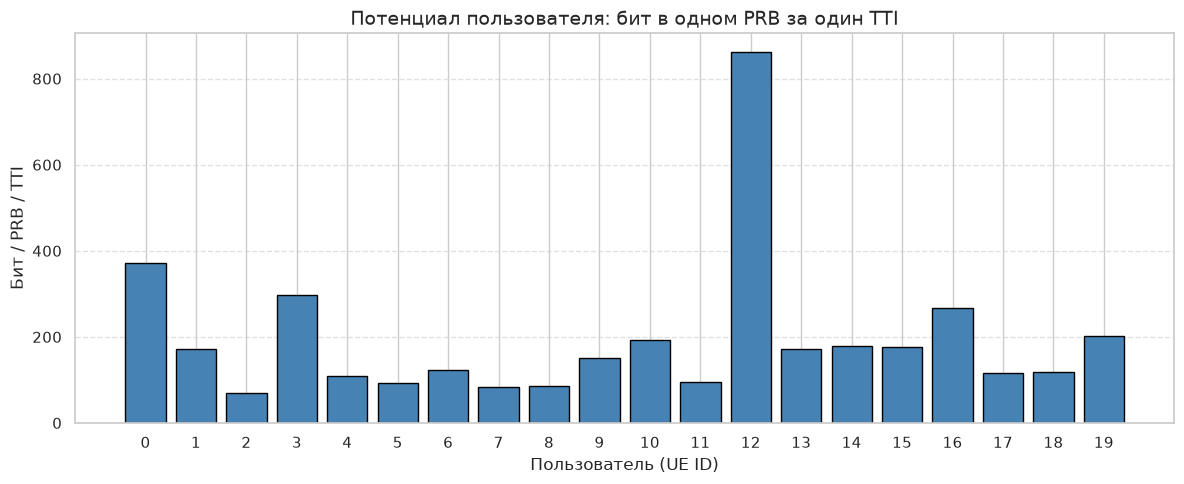

In [86]:
# расчет битов на PRB за 1 TTI (Формула Шеннона)
sinr_linear = 10 ** (sinr_ue_db / 10.0)
se_bps_hz = np.log2(1 + sinr_linear) * efficiency
se_bps_hz = np.minimum(se_bps_hz, max_se)

# бит в PRB на TTI
bits_per_prb_per_tti = se_bps_hz * prb_bandwidth_hz * tti_duration_s

plt.figure(figsize=(12, 5))

plt.bar(range(n_users), bits_per_prb_per_tti, color='steelblue', edgecolor='black')

plt.xlabel('Пользователь (UE ID)', fontsize=12)
plt.ylabel('Бит / PRB / TTI', fontsize=12)
plt.title('Потенциал пользователя: бит в одном PRB за один TTI', fontsize=14)
plt.xticks(range(n_users))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Функции планировщика

In [87]:
# Настройка стиля графиков для наглядности
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# Полный буфер: у всех всегда есть данные
buffer_bits = np.full(n_ues, np.inf)

def scheduler_round_robin(tti, n_ues, n_prb, bits_per_prb, buffer_bits, **kwargs):
    grants_prb = np.zeros(n_ues, dtype=int)
    active_ues = np.where(buffer_bits > 0)[0]
    if len(active_ues) == 0: return grants_prb
    # Честный опрос по кругу
    selected_ue = active_ues[tti % len(active_ues)]
    grants_prb[selected_ue] = n_prb
    return grants_prb

def scheduler_max_ci(tti, n_ues, n_prb, bits_per_prb, buffer_bits, **kwargs):
    grants_prb = np.zeros(n_ues, dtype=int)
    active_ues = np.where(buffer_bits > 0)[0]
    if len(active_ues) == 0: return grants_prb
    # Жадный алгоритм: отдаем все ресурсы тому, у кого лучший канал (макс. SINR)
    best_ue = active_ues[np.argmax(bits_per_prb[active_ues])]
    grants_prb[best_ue] = n_prb
    return grants_prb

def scheduler_proportional_fair(tti, n_ues, n_prb, bits_per_prb, buffer_bits, avg_throughput, alpha=0.95):
    grants_prb = np.zeros(n_ues, dtype=int)
    active_ues = np.where(buffer_bits > 0)[0]
    if len(active_ues) == 0: return grants_prb
    
    # PF-метрика = текущий потенциал канала / средняя прошлая пропускная способность
    pf_metric = bits_per_prb / (avg_throughput + 1e-6)
    best_ue = active_ues[np.argmax(pf_metric[active_ues])]
    grants_prb[best_ue] = n_prb
    
    # Обновление скользящего среднего (EMA) для всех пользователей
    # alpha - коэффициент памяти, как быстро планировщик реагирует на изменения.
    current_rates = grants_prb * bits_per_prb
    avg_throughput[:] = alpha * avg_throughput + (1 - alpha) * current_rates
    return grants_prb

algorithms = {
    'Round Robin': scheduler_round_robin,
    'Max C/I': scheduler_max_ci,
    'Proportional Fair': scheduler_proportional_fair
}

In [88]:
def run_mac_simulation(n_ttis, n_ues, n_prb, bits_per_prb, buffer_bits, scheduler_func, pf_alpha=0.95):
    total_bits = np.zeros(n_ues)
    grants_history = np.zeros((n_ttis, n_ues), dtype=int) # Для тепловых карт
    avg_throughput = np.zeros(n_ues)
    
    for tti in range(n_ttis):
        grants = scheduler_func(
            tti, n_ues, n_prb, bits_per_prb, buffer_bits, 
            avg_throughput=avg_throughput, alpha=pf_alpha
        )
        grants_history[tti] = grants
        total_bits += grants * bits_per_prb
        
    return total_bits, grants_history

# Запуск симуляции для всех алгоритмов
results = {}
for name, func in algorithms.items():
    total_bits, history = run_mac_simulation(
        n_ttis, n_ues, n_prb, bits_per_prb_per_tti, buffer_bits, func
    )
    # Переводим в Mbps (Мегабиты в секунду)
    total_mbits = total_bits / 1e6
    throughput_mbps = total_mbits / (simulation_time_ms / 1000.0)
    
    results[name] = {
        'throughput_mbps': throughput_mbps,
        'history': history
    }
    print(f"Симуляция '{name}' завершена.")

Симуляция 'Round Robin' завершена.
Симуляция 'Max C/I' завершена.
Симуляция 'Proportional Fair' завершена.


### Визуализируем

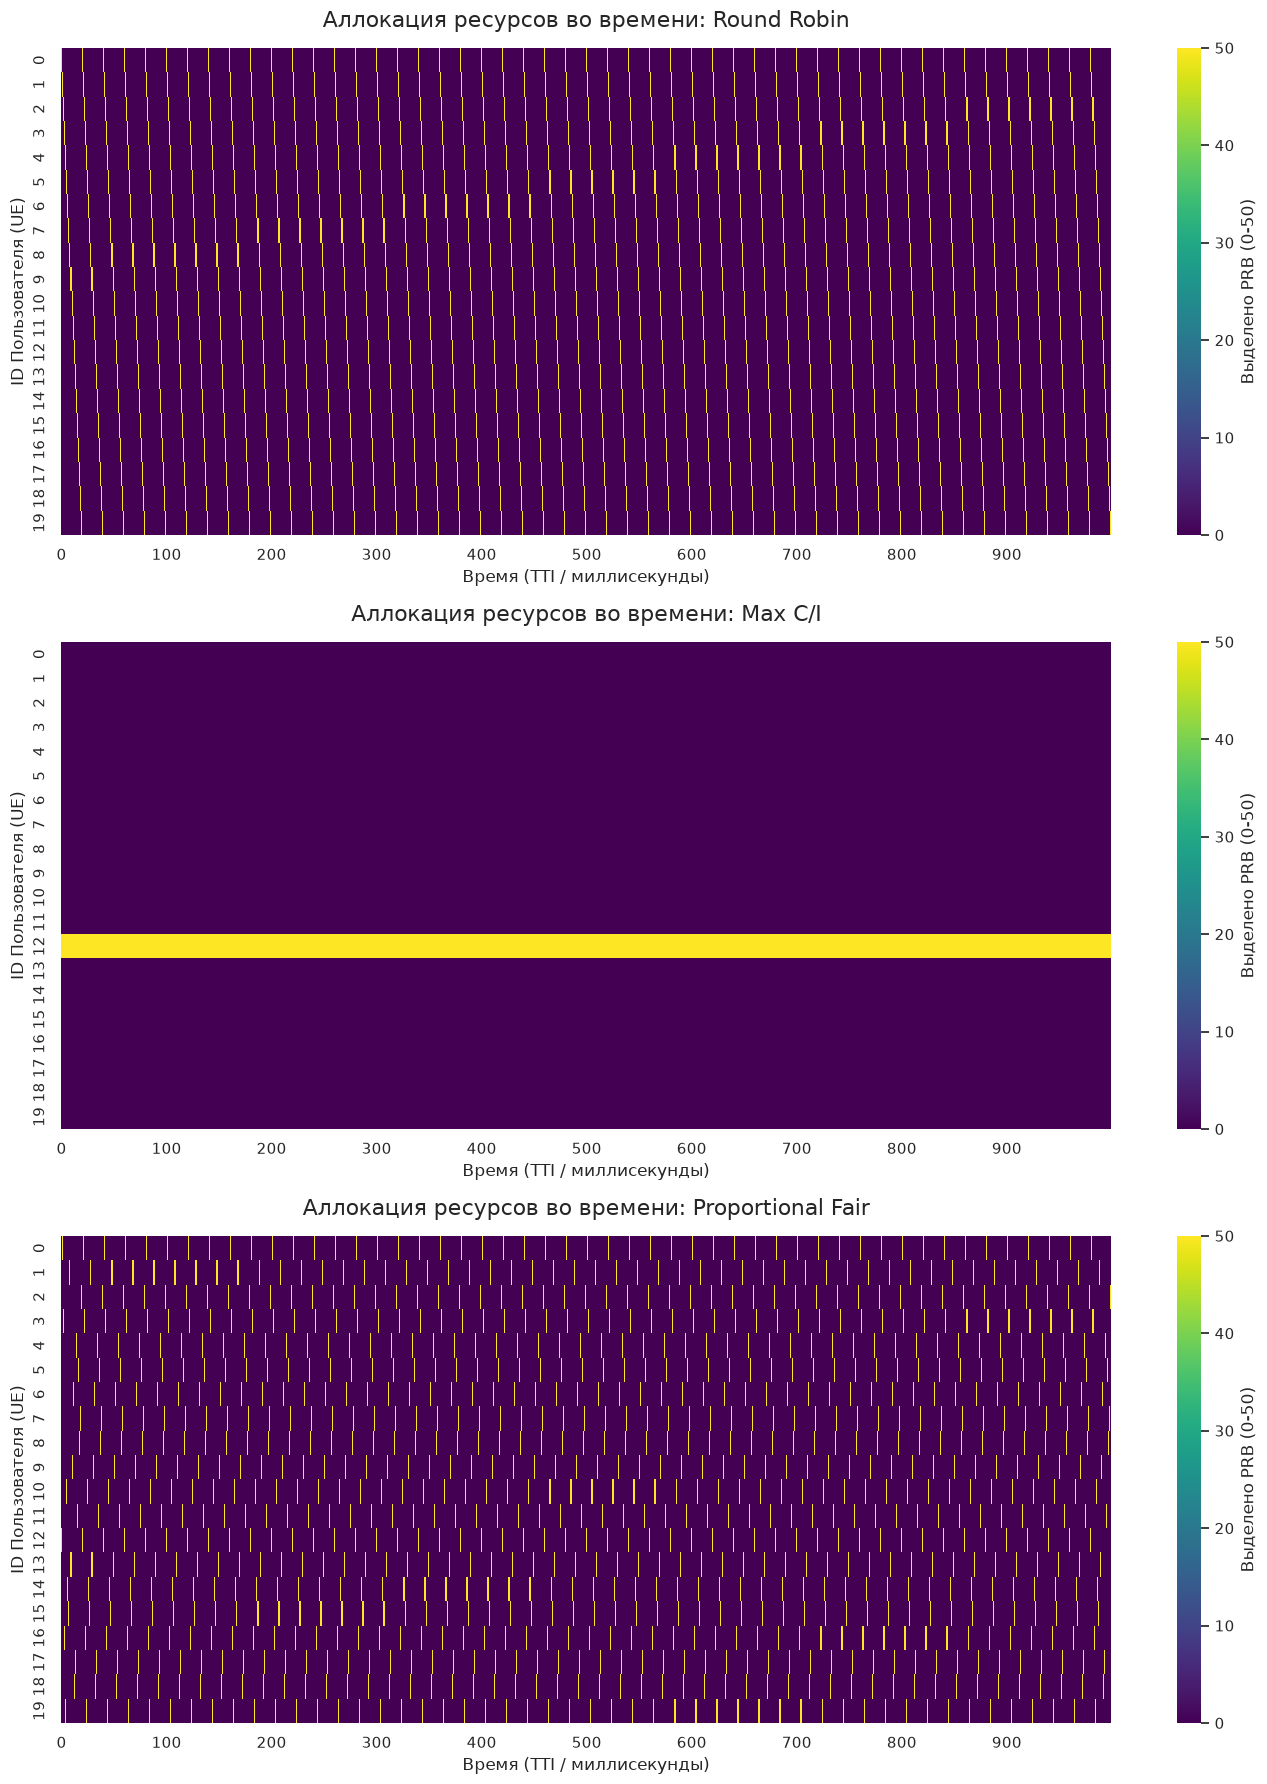

In [89]:
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

for i, (name, data) in enumerate(results.items()):
    ax = axes[i]
    history = data['history']
    
    # history.T транспонирует матрицу: ось Y = Пользователи, ось X = Время (TTI)
    sns.heatmap(
        history.T, 
        ax=ax,
        cmap='viridis',
        cbar_kws={'label': 'Выделено PRB (0-50)'},
        xticklabels=100, # Показываем метку каждые 100 TTI
        yticklabels=np.arange(0, n_ues)
    )
    
    ax.set_title(f'Аллокация ресурсов во времени: {name}', fontsize=16, pad=15)
    ax.set_xlabel('Время (TTI / миллисекунды)', fontsize=12)
    ax.set_ylabel('ID Пользователя (UE)', fontsize=12)

plt.tight_layout()
plt.show()

Индекс Джейна

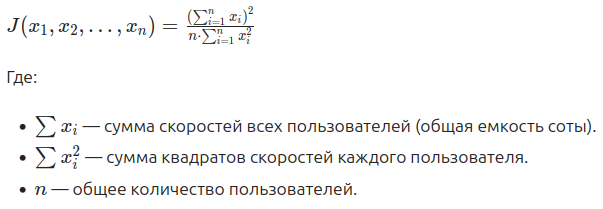

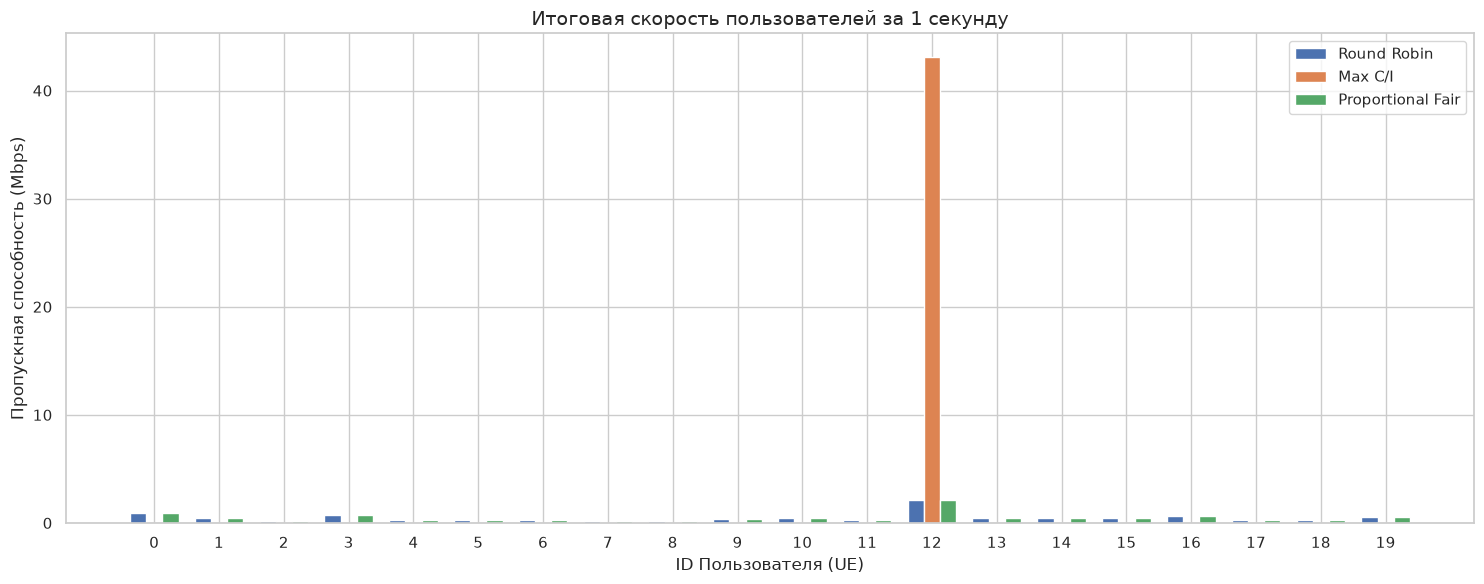

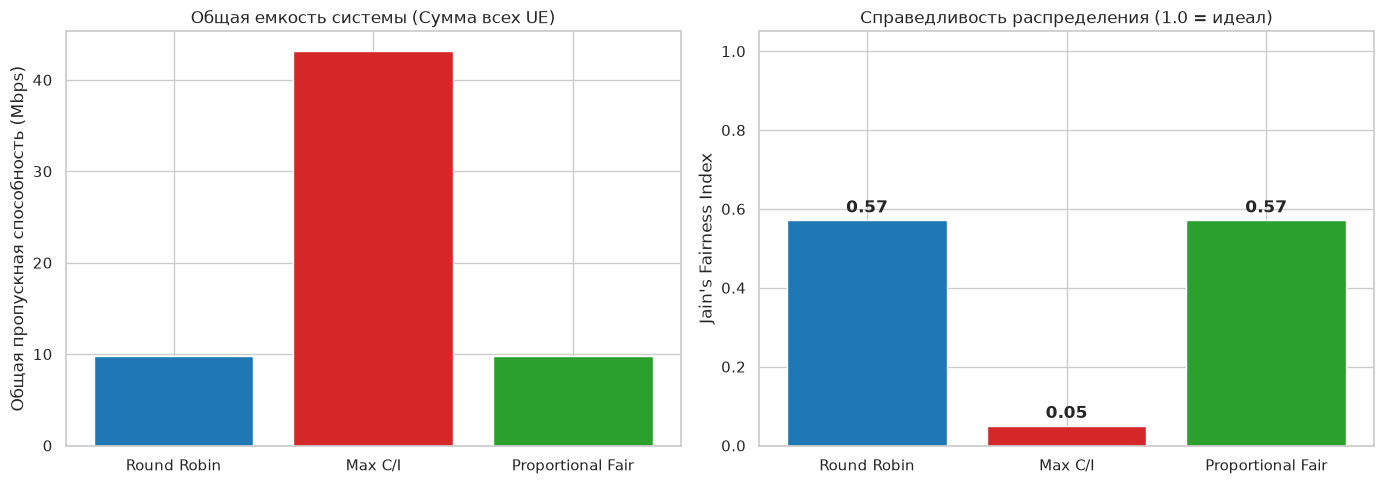

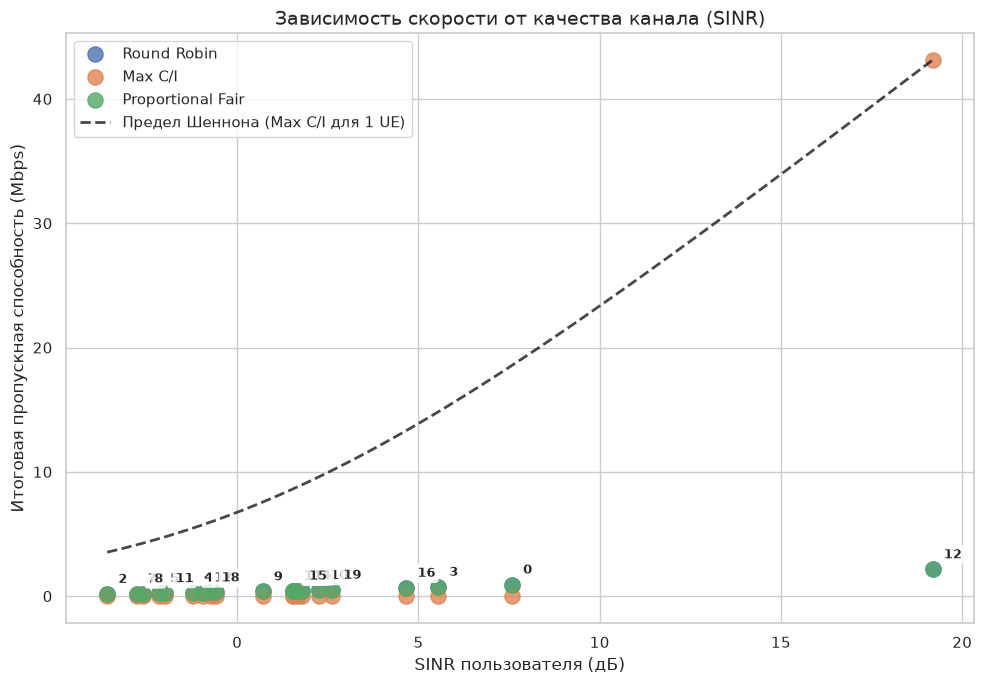

In [92]:
# Итоговая пропускная способность по пользователям
fig, ax = plt.subplots(figsize=(15, 6))
x = np.arange(n_ues)
width = 0.25

for i, name in enumerate(algorithms.keys()):
    ax.bar(x + i*width, results[name]['throughput_mbps'], width, label=name)

ax.set_xlabel('ID Пользователя (UE)', fontsize=12)
ax.set_ylabel('Пропускная способность (Mbps)', fontsize=12)
ax.set_title('Итоговая скорость пользователей за 1 секунду', fontsize=14)
ax.set_xticks(x + width)
ax.set_xticklabels(np.arange(0, n_ues))
ax.legend()
plt.tight_layout()
plt.show()

# Глобальные метрики. Общая емкость vs Индекс Джэйна 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Общая емкость соты
total_tp = [results[name]['throughput_mbps'].sum() for name in algorithms]
colors = ['#1f77b4', '#d62728', '#2ca02c']
axes[0].bar(algorithms.keys(), total_tp, color=colors)
axes[0].set_ylabel('Общая пропускная способность (Mbps)')
axes[0].set_title('Общая емкость системы (Сумма всех UE)')

# Индекс Джэйна 
jain_indices = []
for name in algorithms:
    tp = results[name]['throughput_mbps']
    jain = (np.sum(tp)**2) / (n_ues * np.sum(tp**2))
    jain_indices.append(jain)

axes[1].bar(algorithms.keys(), jain_indices, color=colors)
axes[1].set_ylabel("Jain's Fairness Index")
axes[1].set_title('Справедливость распределения (1.0 = идеал)')
axes[1].set_ylim(0, 1.05)
for i, v in enumerate(jain_indices):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Физический уровень (SINR) vs MAC уровень (Скорость)
fig, ax = plt.subplots(figsize=(10, 7))

for name in algorithms:
    ax.scatter(sinr_ue_db, results[name]['throughput_mbps'], label=name, s=120, alpha=0.8)

# Теоретический предел Шеннона (если бы один UE монопольно владел всеми 50 PRB всю секунду)
sinr_range = np.linspace(min(sinr_ue_db), max(sinr_ue_db), 100)
sinr_lin_range = 10**(sinr_range/10)
se_range = np.minimum(np.log2(1 + sinr_lin_range) * efficiency, max_se)
max_shannon_mbps = (se_range * prb_bandwidth_hz * n_prb) / 1e6

ax.plot(sinr_range, max_shannon_mbps, 'k--', alpha=0.8, linewidth=2, label='Предел Шеннона (Max C/I для 1 UE)')

for i in range(n_users):
    ax.annotate(
        str(i),
        (sinr_ue_db[i], results['Round Robin']['throughput_mbps'][i]),
        fontsize=9,
        fontweight='bold',
        textcoords="offset points", 
        xytext=(8, 8),
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8)
    )

ax.set_xlabel('SINR пользователя (дБ)', fontsize=12)
ax.set_ylabel('Итоговая пропускная способность (Mbps)', fontsize=12)
ax.set_title('Зависимость скорости от качества канала (SINR)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()